In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/AirQualityUCI.csv",
    sep=";",
    decimal=",",
    encoding="latin1"
)

# Remove empty columns included in some dataset versions
df = df.dropna(axis=1, how="all")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())
df.info()

Dataset shape: (9471, 15)

Column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [2]:
# Convert measurement columns to numeric values
for col in df.columns:
    if col not in ["Date", "Time"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# The dataset uses -200 to indicate missing readings
df = df.replace(-200, np.nan)

print("Missing values by column:")
print(df.isna().sum().sort_values(ascending=False))

Missing values by column:
NMHC(GT)         8557
CO(GT)           1797
NO2(GT)          1756
NOx(GT)          1753
PT08.S2(NMHC)     480
C6H6(GT)          480
PT08.S1(CO)       480
PT08.S5(O3)       480
T                 480
PT08.S3(NOx)      480
PT08.S4(NO2)      480
RH                480
AH                480
Date              114
Time              114
dtype: int64


In [3]:
df["datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

df = (
    df.dropna(subset=["datetime"])
      .sort_values("datetime")
      .reset_index(drop=True)
)

# Remove duplicate timestamps if any
df = df.drop_duplicates(subset="datetime").reset_index(drop=True)

print("Date range:", df["datetime"].min(), "to", df["datetime"].max())
print("Rows after timestamp cleaning:", len(df))

Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Rows after timestamp cleaning: 9357


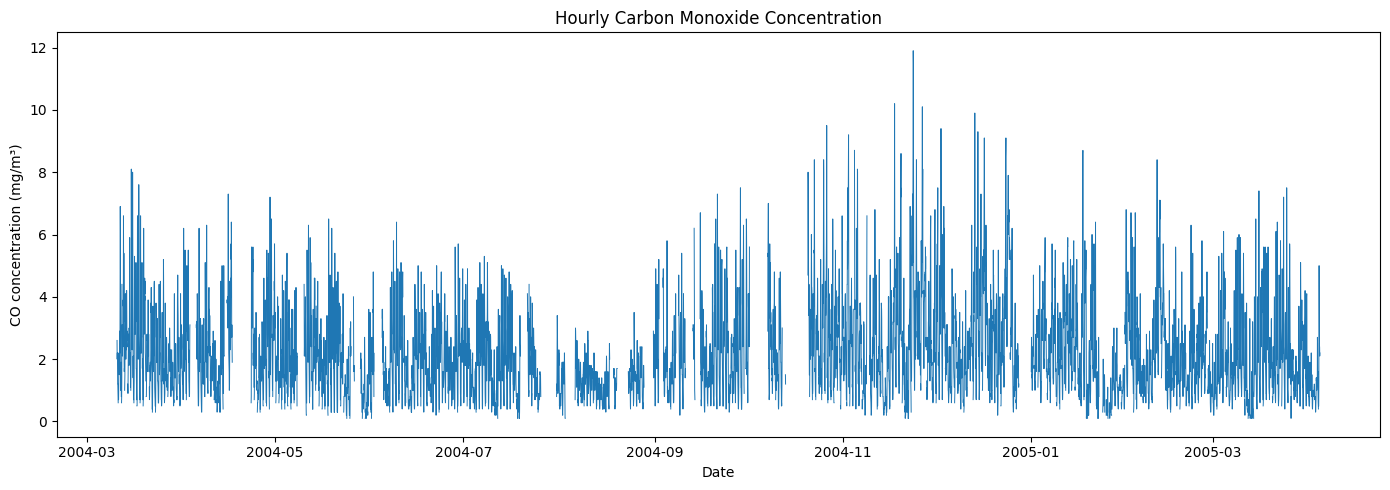

In [4]:
plt.figure(figsize=(14, 5))
plt.plot(df["datetime"], df["CO(GT)"], linewidth=0.7)
plt.title("Hourly Carbon Monoxide Concentration")
plt.xlabel("Date")
plt.ylabel("CO concentration (mg/m³)")
plt.tight_layout()
plt.show()

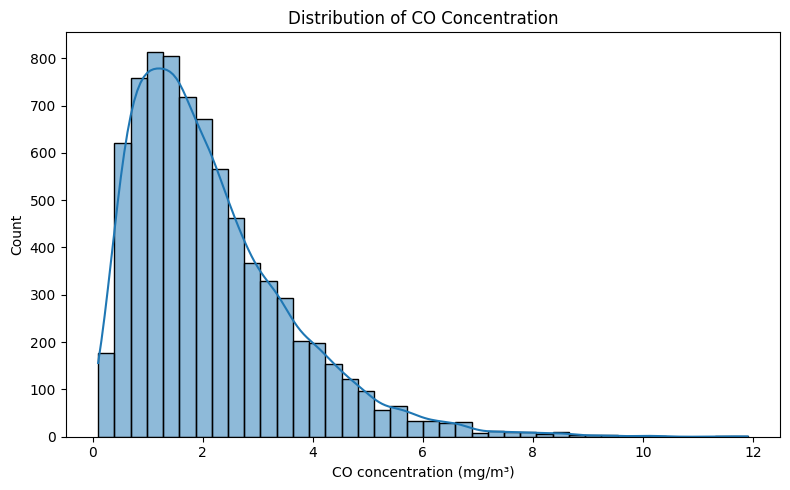

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["CO(GT)"].dropna(), bins=40, kde=True)
plt.title("Distribution of CO Concentration")
plt.xlabel("CO concentration (mg/m³)")
plt.tight_layout()
plt.show()

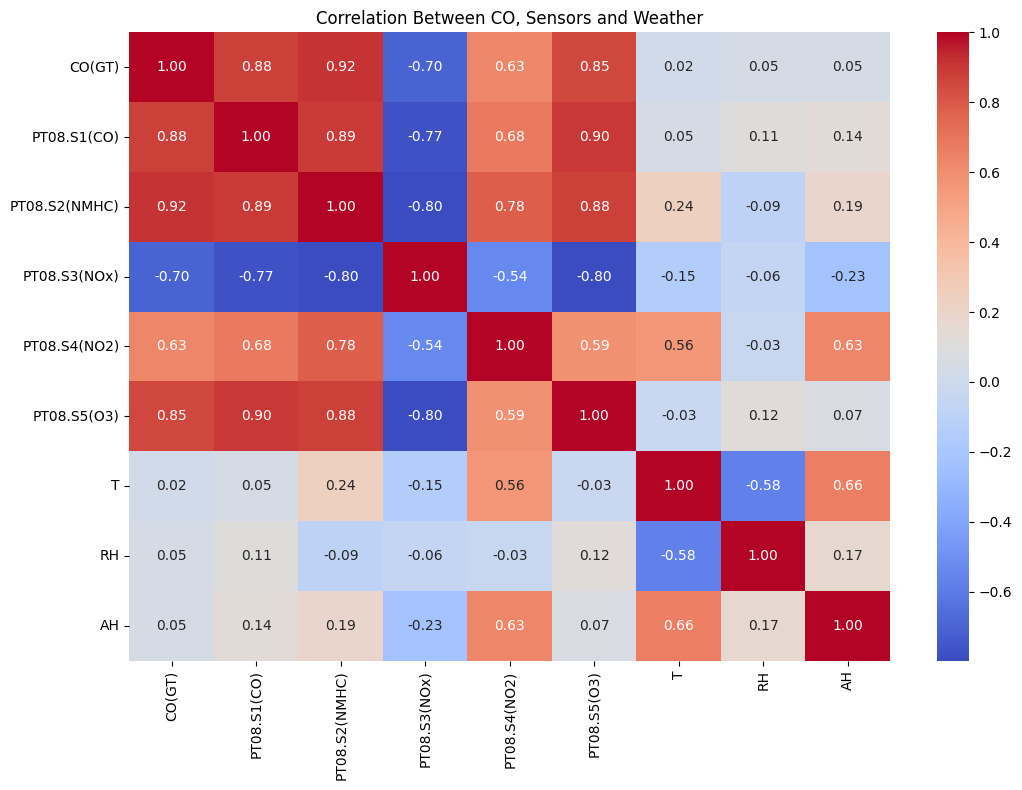

In [6]:
columns = [
    "CO(GT)",
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

plt.figure(figsize=(11, 8))
sns.heatmap(
    df[columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between CO, Sensors and Weather")
plt.tight_layout()
plt.show()

In [7]:
df["hour"] = df["datetime"].dt.hour
df["month"] = df["datetime"].dt.month

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

In [8]:
features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

target = "CO(GT)"

# Remove rows where the target is unknown
data = df.dropna(subset=[target]).copy()

X = data[features]
y = data[target]

print("Usable observations:", len(data))
print("Number of input features:", len(features))
print("Target:", target)

Usable observations: 7674
Number of input features: 12
Target: CO(GT)


In [9]:
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 5371
Validation rows: 1151
Testing rows: 1152


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Median baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="median"))
    ]),

    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Neural Network": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=False,
            random_state=42
        ))
    ])
}

In [11]:
def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

validation_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    validation_results.append({
        "Model": name,
        **calculate_metrics(y_val, predictions)
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results.sort_values("RMSE"))

,Model,MAE,RMSE,R2
1,Linear Regression,0.632066,0.902711,0.661732
2,Random Forest,0.573637,0.908328,0.657510
3,Neural Network,0.672108,0.958819,0.618376
0,Median baseline,1.188445,1.607846,-0.073128


In [12]:
from sklearn.base import clone

architectures = {
    "Small MLP": (32,),
    "Medium MLP": (64, 32),
    "Larger MLP": (128, 64, 32)
}

architecture_results = []

for name, layers in architectures.items():
    experiment = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=layers,
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=False,
            random_state=42
        ))
    ])

    experiment.fit(X_train, y_train)
    pred = experiment.predict(X_val)

    architecture_results.append({
        "Architecture": name,
        **calculate_metrics(y_val, pred)
    })

architecture_results = pd.DataFrame(architecture_results)
display(architecture_results.sort_values("RMSE"))

,Architecture,MAE,RMSE,R2
0,Small MLP,0.616654,0.900692,0.663244
1,Medium MLP,0.672108,0.958819,0.618376
2,Larger MLP,0.740349,1.063928,0.530120


In [13]:
alpha_values = [0.0001, 0.001, 0.01, 0.1]

regularization_results = []

for alpha in alpha_values:
    experiment = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=alpha,
            max_iter=500,
            random_state=42
        ))
    ])

    experiment.fit(X_train, y_train)
    pred = experiment.predict(X_val)

    regularization_results.append({
        "Alpha": alpha,
        **calculate_metrics(y_val, pred)
    })

regularization_results = pd.DataFrame(regularization_results)
display(regularization_results.sort_values("RMSE"))

,Alpha,MAE,RMSE,R2
1,0.0010,0.672108,0.958819,0.618376
2,0.0100,0.664639,0.962018,0.615825
3,0.1000,0.678704,0.974984,0.605399
0,0.0001,0.686362,0.978932,0.602197


In [14]:
sensor_features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)"
]

all_features = sensor_features + [
    "T", "RH", "AH",
    "hour_sin", "hour_cos",
    "month_sin", "month_cos"
]

feature_experiment_results = []

for name, feature_set in [
    ("Sensors only", sensor_features),
    ("Sensors + weather + time", all_features)
]:
    experiment = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=0.001,
            max_iter=500,
            random_state=42
        ))
    ])

    experiment.fit(X_train[feature_set], y_train)
    pred = experiment.predict(X_val[feature_set])

    feature_experiment_results.append({
        "Features": name,
        **calculate_metrics(y_val, pred)
    })

display(
    pd.DataFrame(feature_experiment_results).sort_values("RMSE")
)

,Features,MAE,RMSE,R2
1,Sensors + weather + time,0.672108,0.958819,0.618376
0,Sensors only,0.664841,0.971656,0.608089


In [15]:
from sklearn.base import clone

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

final_results = []
fitted_models = {}

for name, model in models.items():
    final_model = clone(model)

    final_model.fit(X_train_val, y_train_val)
    predictions = final_model.predict(X_test)

    final_results.append({
        "Model": name,
        **calculate_metrics(y_test, predictions)
    })

    fitted_models[name] = final_model

final_results = pd.DataFrame(final_results)
display(final_results.sort_values("RMSE"))

,Model,MAE,RMSE,R2
2,Random Forest,0.319044,0.483416,0.856107
3,Neural Network,0.409024,0.562048,0.805489
1,Linear Regression,0.600388,0.722646,0.678451
0,Median baseline,0.977517,1.274608,-0.000346


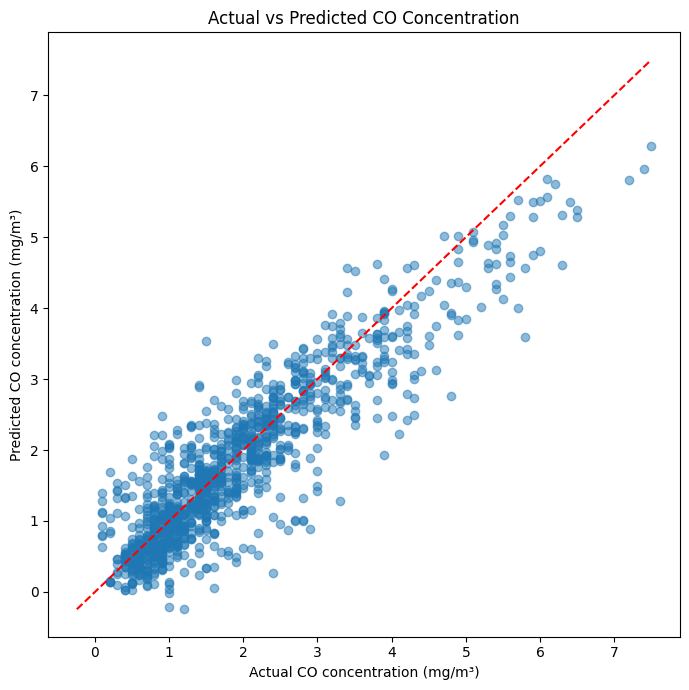

In [16]:
final_nn = fitted_models["Neural Network"]
test_predictions = final_nn.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, test_predictions, alpha=0.5)

limits = [
    min(y_test.min(), test_predictions.min()),
    max(y_test.max(), test_predictions.max())
]

plt.plot(limits, limits, "r--")
plt.xlabel("Actual CO concentration (mg/m³)")
plt.ylabel("Predicted CO concentration (mg/m³)")
plt.title("Actual vs Predicted CO Concentration")
plt.tight_layout()
plt.show()

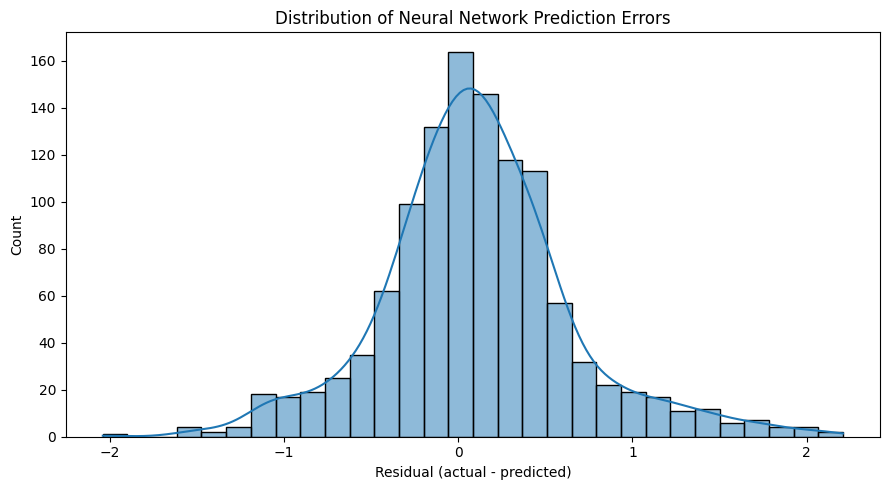

Test MAE: 0.4090241661637739
Test RMSE: 0.5620481122314429
Test R²: 0.805489280117031


In [17]:
residuals = y_test - test_predictions

plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Residual (actual - predicted)")
plt.title("Distribution of Neural Network Prediction Errors")
plt.tight_layout()
plt.show()

print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print(
    "Test RMSE:",
    np.sqrt(mean_squared_error(y_test, test_predictions))
)
print("Test R²:", r2_score(y_test, test_predictions))